У цьому домашньому завданні ми будемо працювати з набором даних Tips. Нижче інформація про нього.

**Про датасет:**

Tips - це датасет, який містить інформацію про рахунки та чайові в ресторані.

**Колонки датасету:**
- `total_bill` - загальна сума рахунку (долари)
- `tip` - розмір чайових (долари)
- `sex` - стать відвідувача (Male/Female)
- `smoker` - чи курить (Yes/No)
- `day` - день тижня (Thur/Fri/Sat/Sun)
- `time` - час відвідування (Lunch/Dinner)
- `size` - розмір групи (кількість людей)

**Джерело:** Оригінальні дані зібрані в одному з американських ресторанів у 1990-х роках. Скачати і переглянути набір даних можна тут: https://www.kaggle.com/datasets/sakshisatre/tips-dataset

А також ми вже вивантажили файл з даними і завантажили вам у Матеріали до цього модуля.




**1. Гістограма розподілу рахунків**
Завантажте датасет Tips (Чайові) з файла у матеріалах `tips.csv`.
Створіть гістограму для колонки `total_bill` з 20 bins.
Опціонально можна додати підписи осей ОХ, ОУ, а також назву графіку.

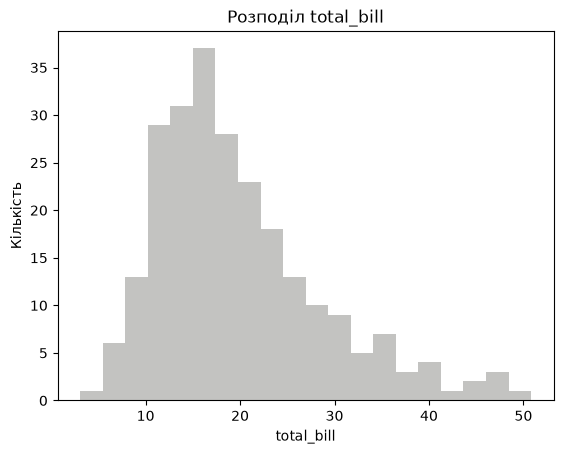

In [60]:
import pandas as pd
import matplotlib.pyplot as plt

tips_data = pd.read_csv('tip.csv')

plt.hist(tips_data['total_bill'], bins=20, color='#AAAAA7', alpha=0.7)
plt.title('Розподіл total_bill')
plt.xlabel('total_bill')
plt.ylabel('Кількість')
plt.show()


---

**2. Box plot чайових за днями тижня**

Створіть box plot, який показує розподіл чайових (`tip`) за днями тижня (`day`).
В який день навище медіанне значення чайоивх? Зелена горизонтальна лінія всередині кожного box-plot.


      count      mean       std   min     25%    50%     75%    max
day                                                                
Fri    19.0  2.734737  1.019577  1.00  1.9600  3.000  3.3650   4.73
Sat    87.0  2.993103  1.631014  1.00  2.0000  2.750  3.3700  10.00
Sun    76.0  3.255132  1.234880  1.01  2.0375  3.150  4.0000   6.50
Thur   62.0  2.771452  1.240223  1.25  2.0000  2.305  3.3625   6.70


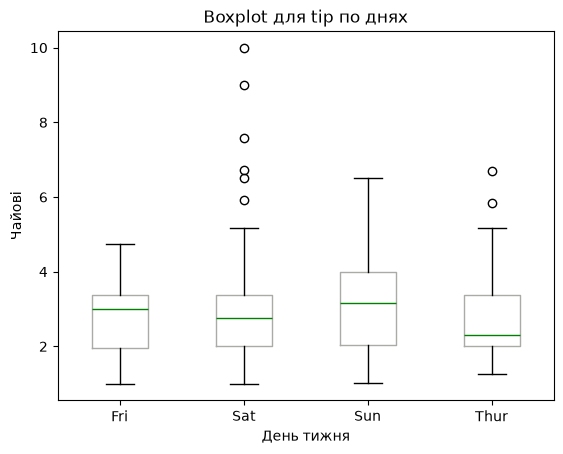

In [120]:
import pandas as pd
import matplotlib.pyplot as plt

tips_data = pd.read_csv('tip.csv')
tips_by_day = tips_data.groupby('day')['tip']
print(tips_by_day.describe())

grouped_data = [tips_by_day.get_group(day) for day in tips_by_day.groups]
plt.boxplot(grouped_data, boxprops=dict(color='#AAAAA7'), medianprops=dict(color='green'))
plt.title('Boxplot для tip по днях')
plt.xlabel('День тижня')
plt.xticks(range(1, len(tips_by_day.groups) + 1), tips_by_day.groups.keys())
plt.ylabel('Чайові')
plt.show()


---

**3. Scatter plot: рахунок vs чайові**

Створіть діаграму розсіювання для `total_bill` та `tip`.

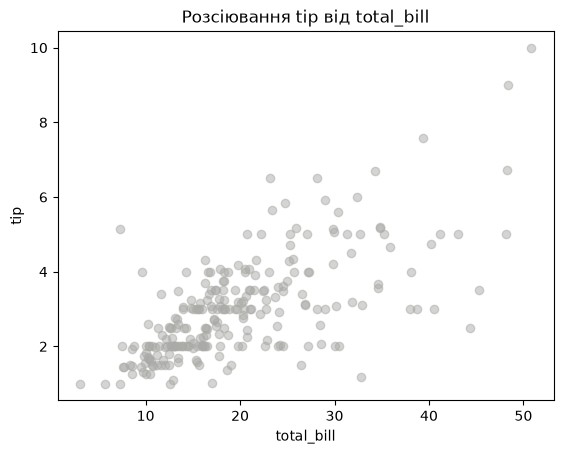

In [62]:
import pandas as pd
import matplotlib.pyplot as plt

tips_data = pd.read_csv('tip.csv')

plt.scatter(x=tips_data['total_bill'], y=tips_data['tip'], alpha=0.5, color='#AAAAA7')
plt.title('Розсіювання tip від total_bill')
plt.xlabel('total_bill')
plt.ylabel('tip')
plt.show()

---

**4. Bar chart: середній рахунок за часом**

Створіть стовпчасту діаграму середнього рахунку за часом дня (`time`).

       total_bill
             mean
time             
Dinner  20.797159
Lunch   17.168676


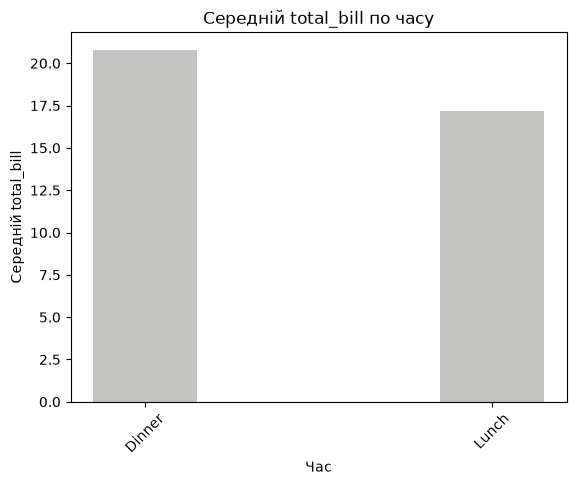

In [119]:
import pandas as pd
import matplotlib.pyplot as plt

tips_data = pd.read_csv('tip.csv')

def agg_func_by_group(data, group_col, value_col, agg_func):
    return data.groupby(group_col).agg({value_col: [agg_func]})

bill_by_time_data = tips_data.groupby('time').agg({'total_bill': ['mean']})
# agg_func_by_group(tips_data, 'time', 'total_bill', 'mean')

print(bill_by_time_data)

# bill_by_time_data.plot(kind='bar', legend=False, color="#D7D738", alpha=0.7)
plt.bar(bill_by_time_data.index, bill_by_time_data.values.flatten(), color='#AAAAA7', alpha=0.7, width=0.3)
plt.title('Середній total_bill по часу')
plt.xlabel('Час')
plt.xticks(rotation=45)
plt.ylabel('Середній total_bill')
plt.show()

---

**5. Інтерактивна діаграма розсіювання**

Створіть з допомогою бібліотек Plotly інтерактивний scatter plot для `total_bill` vs `tip` з кольором за статтю (`sex`).


In [158]:
import pandas as pd
import plotly.express as px

tips_data = pd.read_csv('tip.csv')

px.scatter(
    tips_data,
    x='total_bill',
    y='tip',
    size='size',
    color='sex',
    color_discrete_map={'Female': 'red', 'Male': 'green'},
    labels={'sex': 'Стать', 'tip': 'Чайові', 'total_bill': 'Чек', 'day': 'День', 'time': 'Час', 'size': 'Кількість гостей'},
    hover_data=['day', 'time']
    ).show()




---

**6. Інтерактивний box plot: чайові за днями та статтю**

Створіть інтерактивний box plot для чайових за днями тижня з розбивкою за кольором по статі.